<a href="https://colab.research.google.com/github/mirandaurban/tc3009c/blob/main/Cloud/CCBD_Homework_02_pySpark_Curve_Fitting.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# CCBD Homework 02: pySpark Curve Fitting

In [20]:
# @title Imports y configuraciones

from google.colab import files
from pyspark import SparkContext, SparkConf,SQLContext
from pyspark.sql import SparkSession
from pyspark.sql.functions import isnan, when, count, col, lit
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from pyspark.ml.feature import VectorAssembler, PolynomialExpansion
from pyspark.ml.regression import LinearRegression, RandomForestRegressor, GBTRegressor
from pyspark.ml.evaluation import RegressionEvaluator
from pyspark.ml import Pipeline

#Small printing
%precision 2
np.set_printoptions(precision=2)

In [16]:
# @title Crear contexto Spark y SQL Contexts
sc = SparkContext.getOrCreate(SparkConf().setMaster("local[*]"))

spark = SparkSession \
    .builder \
    .getOrCreate()

sqlContext = SQLContext(sc)


/usr/local/lib/python3.13/dist-packages/pyspark/sql/context.py:112: FutureWarning: Deprecated in 3.0.0. Use SparkSession.builder.getOrCreate() instead.
  warnings.warn(


In [17]:
# @title Importar Google Drive

#Mount Google drive, read local file. The file was previously uploaded to Google Drive
from google.colab import drive
drive.mount("/content/drive")
%ls

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
drive/  sample_data/


In [18]:
# @title Importar el dataset

path_csv="drive/My Drive/Colab Notebooks/cn/bike_sharing_daily.csv"
dataset = sqlContext.read.csv(path_csv,header=True,inferSchema=True)
dataset.printSchema()
print("Dimensiones del dataframe: ",dataset.count(), "x", len(dataset.columns))
dataset.show(10)

root
 |-- instant: integer (nullable = true)
 |-- dteday: date (nullable = true)
 |-- season: integer (nullable = true)
 |-- yr: integer (nullable = true)
 |-- mnth: integer (nullable = true)
 |-- holiday: integer (nullable = true)
 |-- weekday: integer (nullable = true)
 |-- workingday: integer (nullable = true)
 |-- weathersit: integer (nullable = true)
 |-- temp: double (nullable = true)
 |-- atemp: double (nullable = true)
 |-- hum: double (nullable = true)
 |-- windspeed: double (nullable = true)
 |-- casual: integer (nullable = true)
 |-- registered: integer (nullable = true)
 |-- cnt: integer (nullable = true)

Dimensiones del dataframe:  731 x 16
+-------+----------+------+---+----+-------+-------+----------+----------+--------+--------+--------+---------+------+----------+----+
|instant|    dteday|season| yr|mnth|holiday|weekday|workingday|weathersit|    temp|   atemp|     hum|windspeed|casual|registered| cnt|
+-------+----------+------+---+----+-------+-------+----------+----

In [19]:
columnas_dataset = dataset.columns
columnas_dataset

['instant',
 'dteday',
 'season',
 'yr',
 'mnth',
 'holiday',
 'weekday',
 'workingday',
 'weathersit',
 'temp',
 'atemp',
 'hum',
 'windspeed',
 'casual',
 'registered',
 'cnt']

In [21]:
df = dataset.select("weathersit", "cnt").dropna()

train_data, test_data = df.randomSplit([0.8, 0.2], seed=42)

evaluator = RegressionEvaluator(
    labelCol="cnt", predictionCol="prediction", metricName="rmse"
)

def evaluate_model(pred_df, name):
    return {
        "model": name,
        "RMSE": evaluator.evaluate(pred_df),
        "MSE":  evaluator.evaluate(pred_df, {evaluator.metricName: "mse"}),
        "MAE":  evaluator.evaluate(pred_df, {evaluator.metricName: "mae"}),
        "R2":   evaluator.evaluate(pred_df, {evaluator.metricName: "r2"}),
    }

results = []

In [22]:
# @title Linear Regression
for degree in range(1, 6):
    pipeline = Pipeline(stages=[
        VectorAssembler(inputCols=["weathersit"], outputCol="raw_features"),
        PolynomialExpansion(degree=degree, inputCol="raw_features", outputCol="features"),
        LinearRegression(featuresCol="features", labelCol="cnt"),
    ])
    model = pipeline.fit(train_data)
    preds = model.transform(test_data)
    res = evaluate_model(preds, f"LinearReg (deg={degree})")
    results.append(res)
    print(f"degree={degree}: RMSE={res['RMSE']:.4f}  R2={res['R2']:.4f}")

degree=1: RMSE=1914.6265  R2=0.0740
degree=2: RMSE=1892.9326  R2=0.0949
degree=3: RMSE=1892.9326  R2=0.0949
degree=4: RMSE=1892.9326  R2=0.0949
degree=5: RMSE=1892.9326  R2=0.0949


In [23]:
# @title Random Forest
for degree in range(1, 6):
    pipeline = Pipeline(stages=[
        VectorAssembler(inputCols=["weathersit"], outputCol="raw_features"),
        PolynomialExpansion(degree=degree, inputCol="raw_features", outputCol="features"),
        RandomForestRegressor(featuresCol="features", labelCol="cnt",
                              numTrees=100, maxDepth=5, seed=42),
    ])
    model = pipeline.fit(train_data)
    preds = model.transform(test_data)
    res = evaluate_model(preds, f"RandomForest (deg={degree})")
    results.append(res)
    print(f"degree={degree}: RMSE={res['RMSE']:.4f}  R2={res['R2']:.4f}")

degree=1: RMSE=1890.2528  R2=0.0974
degree=2: RMSE=1890.2528  R2=0.0974
degree=3: RMSE=1890.2528  R2=0.0974
degree=4: RMSE=1890.2528  R2=0.0974
degree=5: RMSE=1890.2528  R2=0.0974


In [24]:
# @title GBT: degree sweep
for degree in range(1, 6):
    pipeline = Pipeline(stages=[
        VectorAssembler(inputCols=["weathersit"], outputCol="raw_features"),
        PolynomialExpansion(degree=degree, inputCol="raw_features", outputCol="features"),
        GBTRegressor(featuresCol="features", labelCol="cnt",
                     maxIter=100, maxDepth=5, seed=42),
    ])
    model = pipeline.fit(train_data)
    preds = model.transform(test_data)
    res = evaluate_model(preds, f"GBT (deg={degree})")
    results.append(res)
    print(f"degree={degree}: RMSE={res['RMSE']:.4f}  R2={res['R2']:.4f}")

degree=1: RMSE=1892.9326  R2=0.0949
degree=2: RMSE=1892.9326  R2=0.0949
degree=3: RMSE=1892.9326  R2=0.0949
degree=4: RMSE=1892.9326  R2=0.0949
degree=5: RMSE=1892.9326  R2=0.0949


In [25]:
# @title Resultados
results_df = pd.DataFrame(results).sort_values("R2", ascending=False)
print(" Ranked results (best fit on top)")
print(results_df.to_string(index=False, float_format=lambda x: f"{x:.4f}"))

best = results_df.iloc[0]
print(f"\nBest configuration: {best['model']}  →  RMSE={best['RMSE']:.4f}, R2={best['R2']:.4f}")

 Ranked results (best fit on top)
               model      RMSE          MSE       MAE     R2
RandomForest (deg=2) 1890.2528 3573055.6934 1526.4364 0.0974
RandomForest (deg=1) 1890.2528 3573055.6934 1526.4364 0.0974
RandomForest (deg=3) 1890.2528 3573055.6934 1526.4364 0.0974
RandomForest (deg=4) 1890.2528 3573055.6934 1526.4364 0.0974
RandomForest (deg=5) 1890.2528 3573055.6934 1526.4364 0.0974
         GBT (deg=1) 1892.9326 3583194.0114 1528.2192 0.0949
         GBT (deg=2) 1892.9326 3583194.0114 1528.2192 0.0949
         GBT (deg=4) 1892.9326 3583194.0114 1528.2192 0.0949
         GBT (deg=3) 1892.9326 3583194.0114 1528.2192 0.0949
         GBT (deg=5) 1892.9326 3583194.0114 1528.2192 0.0949
   LinearReg (deg=2) 1892.9326 3583194.0114 1528.2192 0.0949
   LinearReg (deg=3) 1892.9326 3583194.0114 1528.2192 0.0949
   LinearReg (deg=4) 1892.9326 3583194.0114 1528.2192 0.0949
   LinearReg (deg=5) 1892.9326 3583194.0114 1528.2192 0.0949
   LinearReg (deg=1) 1914.6265 3665794.7548 1552.25

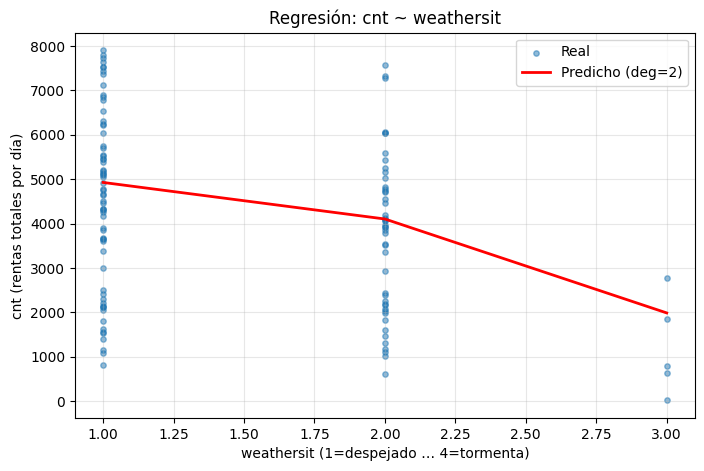

In [26]:
# Gráfica para mejor interpretación
import matplotlib.pyplot as plt

# Reentrenamos la configuración ganadora (ajusta el grado si cambia)
assembler = VectorAssembler(inputCols=["weathersit"], outputCol="raw_features")
poly      = PolynomialExpansion(degree=2, inputCol="raw_features", outputCol="features")
lr        = LinearRegression(featuresCol="features", labelCol="cnt")
best_model = Pipeline(stages=[assembler, poly, lr]).fit(train_data)

preds_pd = best_model.transform(test_data).select("weathersit", "cnt", "prediction").toPandas()

plt.figure(figsize=(8,5))
plt.scatter(preds_pd["weathersit"], preds_pd["cnt"], s=15, alpha=0.5, label="Real")
preds_sorted = preds_pd.sort_values("weathersit")
plt.plot(preds_sorted["weathersit"], preds_sorted["prediction"],
         color="red", lw=2, label="Predicho (deg=2)")
plt.xlabel("weathersit (1=despejado … 4=tormenta)")
plt.ylabel("cnt (rentas totales por día)")
plt.title("Regresión: cnt ~ weathersit")
plt.legend(); plt.grid(alpha=0.3); plt.show()

**Conclusión:** El mejor modelo fue Random Forest de grado 2, con el error más bajo (RMSE = 1890.25) y la mejor explicación de los datos (R² = 0.0974), aunque el margen sobre GBT y la Regresión Lineal de grado 2 es mínimo. Lo interesante es que todos los modelos dan un R² muy bajo (alrededor del 0.10), lo que significa que el clima por sí solo explica apenas el 10% de las rentas diarias de bicicletas. Hay otros factores (estación del año, temperatura, día laboral, año, etc.) que pesan mucho más y por ende, que son más relevante para un análisis que busque optimizar el nivel de rentas. Además, weathersit solo tiene 4 valores posibles, así que aumentar el grado del polinomio no aporta nada nuevo. La conclusión para el equipo de Capital Bikeshare es que:
> las condiciones climáticas no bastan para predecir la demanda, se necesita un modelo con más variables para que sea realmente útil.

